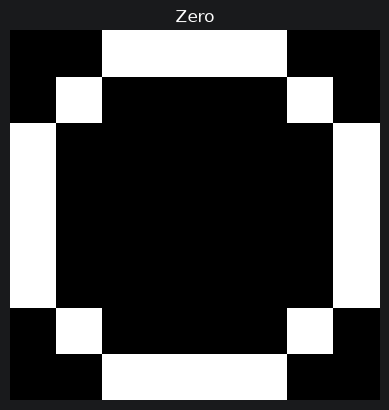

In [35]:
from base64 import standard_b64decode

import numpy as np
import matplotlib.pyplot as plt

wzorzec_0 = np.array([
    [0, 0, 1, 1, 1, 1, 0, 0],
    [0, 1, 0, 0, 0, 0, 1, 0],
    [1, 0, 0, 0, 0, 0, 0, 1],
    [1, 0, 0, 0, 0, 0, 0, 1],
    [1, 0, 0, 0, 0, 0, 0, 1],
    [1, 0, 0, 0, 0, 0, 0, 1],
    [0, 1, 0, 0, 0, 0, 1, 0],
    [0, 0, 1, 1, 1, 1, 0, 0]
])

wzorzec_0 = np.where(wzorzec_0 == 0, -1, 1)

plt.imshow(wzorzec_0, cmap='gray')
plt.title('Zero')
plt.axis('off')
plt.show()


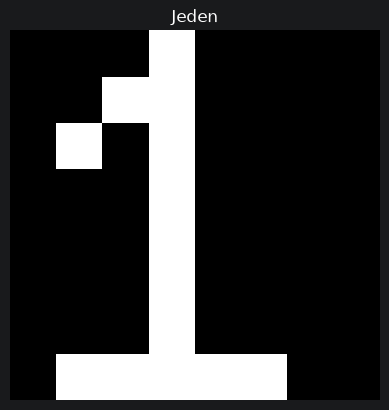

In [36]:
wzorzec_1 = np.array([
    [0, 0, 0, 1, 0, 0, 0, 0],
    [0, 0, 1, 1, 0, 0, 0, 0],
    [0, 1, 0, 1, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 0, 0]
])

wzorzec_1 = np.where(wzorzec_1 == 0, -1, 1)

plt.imshow(wzorzec_1, cmap='gray')
plt.title('Jeden')
plt.axis('off')
plt.show()


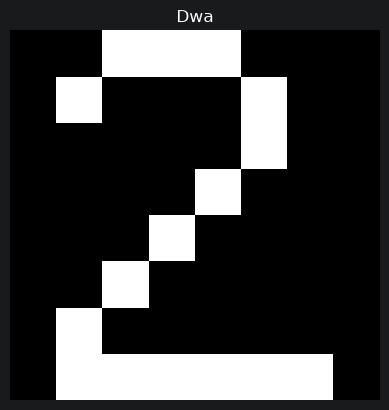

In [37]:
wzorzec_2 = np.array([
    [0, 0, 1, 1, 1, 0, 0, 0],
    [0, 1, 0, 0, 0, 1, 0, 0],
    [0, 0, 0, 0, 0, 1, 0, 0],
    [0, 0, 0, 0, 1, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0, 0, 0],
    [0, 1, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 0]
])
wzorzec_2 = np.where(wzorzec_2 == 0, -1, 1)

plt.imshow(wzorzec_2, cmap='gray')
plt.title('Dwa')
plt.axis('off')
plt.show()


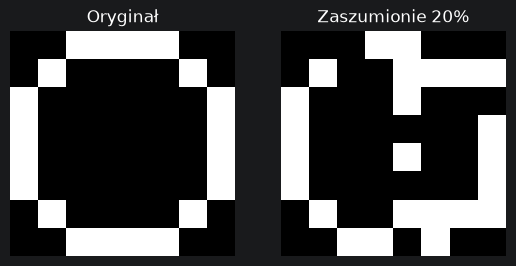

In [38]:
def dodaj_szum(obrazek, procent_szumu):
    zepsuty = obrazek.copy().flatten()

    liczba_zmian = int(64* (procent_szumu / 100.0))

    indeksy_do_zmiany = np.random.choice(64, liczba_zmian, replace=False)

    for indeks in indeksy_do_zmiany:
        zepsuty[indeks] =zepsuty[indeks] * -1

    return zepsuty.reshape(8, 8)

zaszumionie_zero = dodaj_szum(wzorzec_0, 20)

fig, (lewy, prawy) = plt.subplots(1, 2)

lewy.imshow(wzorzec_0, cmap='gray')
lewy.set_title("Oryginał")
lewy.axis('off')

prawy.imshow(zaszumionie_zero, cmap='gray')
prawy.set_title("Zaszumionie 20%")
prawy.axis('off')

plt.show()

In [39]:
wzorce = [wzorzec_0.flatten(), wzorzec_1.flatten(), wzorzec_2.flatten()]
liczba_neuronow = 64

wagi = np.zeros((liczba_neuronow, liczba_neuronow))

print("zaczynamy naukę...")

for wzorzec in wzorce:
    wagi += np.outer(wzorzec, wzorzec)

np.fill_diagonal(wagi, 0)

wagi = wagi / liczba_neuronow

print("Nauka zakończona!\n")

czy_zera_na_przekątnej = np.all(np.diag(wagi) == 0)
print(f"Czy na przekątnej znajdują się zera? {czy_zera_na_przekątnej}")

czy_symetryczna = np.allclose(wagi, wagi.T)
print(f"Czy macierz wag jest symetryczna? {czy_symetryczna}")



zaczynamy naukę...
Nauka zakończona!

Czy na przekątnej znajdują się zera? True
Czy macierz wag jest symetryczna? True


Próba przypomnienia oryginału...
Próba przypomnienia oryginału...


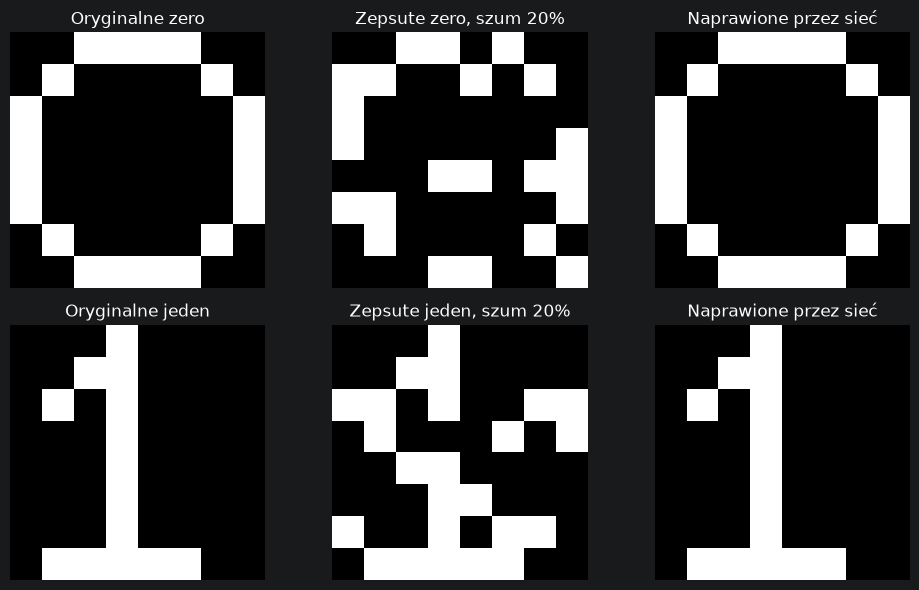

In [40]:
def napraw_obrazek(zaszumiony, macierz_wag, liczba_okrozen=5):
    stan_sieci = zaszumiony.flatten()
    liczba_neuronow = len(stan_sieci)

    print("Próba przypomnienia oryginału...")

    for okrozenia in range(liczba_okrozen):
        for i in range(liczba_neuronow):
            pole_lokalne = np.dot(macierz_wag[i], stan_sieci)

            if pole_lokalne > 0:
                stan_sieci[i] = 1
            elif pole_lokalne < 0:
                stan_sieci[i] = -1

    return stan_sieci.reshape(8,8)

zepsute_0 = dodaj_szum(wzorzec_0, 20)
zepsute_1 = dodaj_szum(wzorzec_1, 20)

naprawione_0 = napraw_obrazek(zepsute_0, wagi)
naprawione_1 = napraw_obrazek(zepsute_1, wagi)

fig, ax = plt.subplots(2, 3, figsize=(10, 6))

ax[0, 0].imshow(wzorzec_0, cmap='gray')
ax[0, 0].set_title("Oryginalne zero")
ax[0, 1].imshow(zepsute_0, cmap='gray')
ax[0, 1].set_title("Zepsute zero, szum 20%")
ax[0, 2].imshow(naprawione_0, cmap='gray')
ax[0, 2].set_title("Naprawione przez sieć")

ax[1, 0].imshow(wzorzec_1, cmap='gray')
ax[1, 0].set_title("Oryginalne jeden")
ax[1, 1].imshow(zepsute_1, cmap='gray')
ax[1, 1].set_title("Zepsute jeden, szum 20%")
ax[1, 2].imshow(naprawione_1, cmap='gray')
ax[1, 2].set_title("Naprawione przez sieć")

for rzad in ax:
    for obraz in rzad:
        obraz.axis("off")

plt.tight_layout()
plt.show()

In [41]:
def napraw_obrazek_po_cichu(zaszumiony, macierz_wag, liczba_okrozen=5):
    stan_sieci = zaszumiony.flatten()
    liczba_neuronow = len(stan_sieci)
    for okrozenia in range(liczba_okrozen):
        for i in range(liczba_neuronow):
            pole_lokalne = np.dot(macierz_wag[i], stan_sieci)
            if pole_lokalne > 0:
                stan_sieci[i] = 1
            elif pole_lokalne < 0:
                stan_sieci[i] = -1
    return stan_sieci.reshape(8, 8)

poziomy_szumu = [10, 20, 30]
ilosc_kopii = [10, 30]
oryginalne_cyfry = [wzorzec_0, wzorzec_1, wzorzec_2]

print("--- Test Hurtowy ---")

for ilosc in ilosc_kopii:
    print(f"\nTestujemy paczki po {ilosc} zaszumionych kopii dla każdej cyfry: ")

    for szum in poziomy_szumu:
        udane_naprawy = 0
        wszystkie_proby = 0

        for oryginal in oryginalne_cyfry:
            for j in range(ilosc):
                zepsuty = dodaj_szum(oryginal, szum)

                naprawiony = napraw_obrazek_po_cichu(zepsuty, wagi)

                if np.array_equal(naprawiony, oryginal):
                    udane_naprawy += 1
                wszystkie_proby += 1

procent_sukcesu = (udane_naprawy / wszystkie_proby) * 100
print(f"Przy szumie {szum} naprawiono {udane_naprawy}/{wszystkie_proby} obrazków (skuteczność: {procent_sukcesu:.1f}%)")

--- Test Hurtowy ---

Testujemy paczki po 10 zaszumionych kopii dla każdej cyfry: 

Testujemy paczki po 30 zaszumionych kopii dla każdej cyfry: 
Przy szumie 30 naprawiono 55/90 obrazków (skuteczność: 61.1%)


Czy macierz pseudoinwersji jest symetryczna? -> True


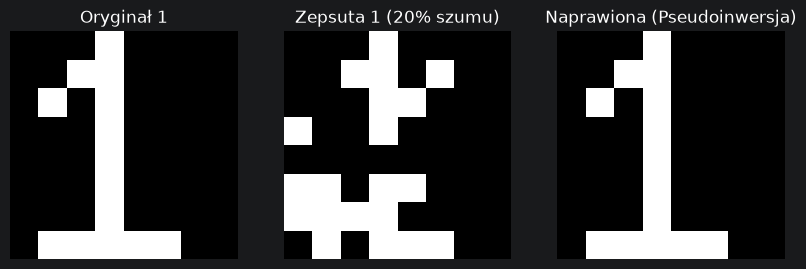

In [42]:
X = np.array([wzorzec_0.flatten(), wzorzec_1.flatten(), wzorzec_2.flatten()])

srodek = np.dot(X, X.T)
pseudoobrotnosc = np.linalg.pinv(srodek)

wagi_pseudo = np.dot(np.dot(X.T, pseudoobrotnosc), X)

np.fill_diagonal(wagi_pseudo, 0)
czy_symetryczna_pseudo = np.allclose(wagi_pseudo, wagi_pseudo.T)
print(f"Czy macierz pseudoinwersji jest symetryczna? -> {czy_symetryczna_pseudo}")

zepsuta_jedynka_test = dodaj_szum(wzorzec_1, 20)
naprawiona_pseudo = napraw_obrazek_po_cichu(zepsuta_jedynka_test, wagi_pseudo)

fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(wzorzec_1, cmap='gray')
ax[0].set_title("Oryginał 1")
ax[1].imshow(zepsuta_jedynka_test, cmap='gray')
ax[1].set_title("Zepsuta 1 (20% szumu)")
ax[2].imshow(naprawiona_pseudo, cmap='gray')
ax[2].set_title("Naprawiona (Pseudoinwersja)")

for obraz in ax:
    obraz.axis('off')
plt.show()

Buduję mózg nr 3 (storkey)


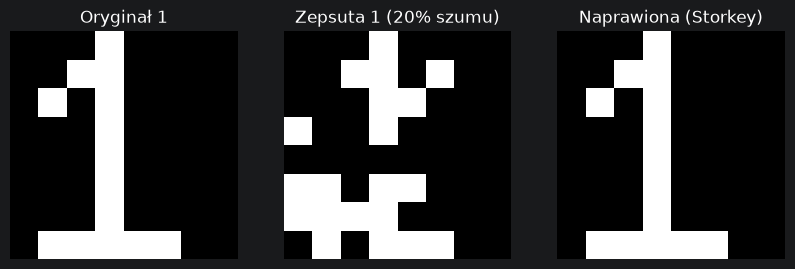

In [43]:
liczba_neuronow = 64
wagi_storkey = np.zeros((liczba_neuronow, liczba_neuronow))
wzorce_plaskie = [wzorzec_0.flatten(), wzorzec_1.flatten(), wzorzec_2.flatten()]

print('Buduję mózg nr 3 (storkey)')

for wzorzec in wzorce_plaskie:
    nowe_wagi = np.copy(wagi_storkey)
    for i in range(liczba_neuronow):
        for j in range(liczba_neuronow):
            h_ij = np.dot(wagi_storkey[i], wzorzec) - wagi_storkey[i, i]*wzorzec[i] - wagi_storkey[i, j]*wzorzec[j]
            h_ji = np.dot(wagi_storkey[j], wzorzec) - wagi_storkey[j, j]*wzorzec[j] - wagi_storkey[j, i]*wzorzec[i]

            nowe_wagi[i, j] += (wzorzec[i] * wzorzec[j] - wzorzec[i] * h_ji - wzorzec[j] * h_ij) / liczba_neuronow
    wagi_storkey = np.copy(nowe_wagi)

np.fill_diagonal(wagi_storkey, 0)

naprawiona_storkey = napraw_obrazek_po_cichu(zepsuta_jedynka_test, wagi_storkey)

fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(wzorzec_1, cmap='gray')
ax[0].set_title("Oryginał 1")
ax[1].imshow(zepsuta_jedynka_test, cmap='gray')
ax[1].set_title("Zepsuta 1 (20% szumu)")
ax[2].imshow(naprawiona_storkey, cmap='gray')
ax[2].set_title("Naprawiona (Storkey)")

for obraz in ax:
    obraz.axis('off')
plt.show()

In [44]:
print("--- WIELKIE STARCIE MÓZGÓW (EKSPERYMENT KOŃCOWY z Lab 4) ---")
poziomy_szumu = [10, 20, 30]
ilosc_prob = 10 # Puszczamy po 10 zepsutych obrazków dla każdej z 3 cyfr (razem 30 na poziom szumu)

for szum in poziomy_szumu:
    sukcesy_hebb = 0
    sukcesy_pseudo = 0
    sukcesy_storkey = 0
    wszystkie_proby = 0

    for oryginal in oryginalne_cyfry:
        for _ in range(ilosc_prob):
            # 1. Psujemy obrazek
            zepsuty = dodaj_szum(oryginal, szum)

            # 2. Każdy z trzech mózgów próbuje go naprawić po swojemu
            naprawiony_hebb = napraw_obrazek_po_cichu(zepsuty, wagi)
            naprawiony_pseudo = napraw_obrazek_po_cichu(zepsuty, wagi_pseudo)
            naprawiony_storkey = napraw_obrazek_po_cichu(zepsuty, wagi_storkey)

            # 3. Sprawdzamy komu się udało zwrócić idealny oryginał
            if np.array_equal(naprawiony_hebb, oryginal): sukcesy_hebb += 1
            if np.array_equal(naprawiony_pseudo, oryginal): sukcesy_pseudo += 1
            if np.array_equal(naprawiony_storkey, oryginal): sukcesy_storkey += 1

            wszystkie_proby += 1

    # 4. Wyświetlanie wyników starcia dla danego poziomu zepsucia
    print(f"\nPoziom szumu: {szum}% (Przetestowano {wszystkie_proby} obrazków)")
    print(f" -> Reguła Hebba (Stara):   {sukcesy_hebb}/{wszystkie_proby} udanych napraw")
    print(f" -> Pseudoinwersja (Nowa):  {sukcesy_pseudo}/{wszystkie_proby} udanych napraw")
    print(f" -> Reguła Storkeya (Nowa): {sukcesy_storkey}/{wszystkie_proby} udanych napraw")

--- WIELKIE STARCIE MÓZGÓW (EKSPERYMENT KOŃCOWY z Lab 4) ---

Poziom szumu: 10% (Przetestowano 30 obrazków)
 -> Reguła Hebba (Stara):   23/30 udanych napraw
 -> Pseudoinwersja (Nowa):  30/30 udanych napraw
 -> Reguła Storkeya (Nowa): 30/30 udanych napraw

Poziom szumu: 20% (Przetestowano 30 obrazków)
 -> Reguła Hebba (Stara):   25/30 udanych napraw
 -> Pseudoinwersja (Nowa):  30/30 udanych napraw
 -> Reguła Storkeya (Nowa): 29/30 udanych napraw

Poziom szumu: 30% (Przetestowano 30 obrazków)
 -> Reguła Hebba (Stara):   15/30 udanych napraw
 -> Pseudoinwersja (Nowa):  29/30 udanych napraw
 -> Reguła Storkeya (Nowa): 27/30 udanych napraw
